# ЛР3. Градиентный спуск (вариант 4)

**Задание:**
1. Сгенерировать датасет `sklearn.datasets.make_regression` (не менее 2 признаков, т.е. не менее 3 весов вместе со свободным членом). При необходимости масштабировать.
2. Самостоятельно написать функцию **градиентного спуска** (не стохастического):
   1. инициализировать начальные веса и ε;
   2. цикл по количеству итераций;
   3. расчёт новых весов: $w^k = w^{k-1} - \eta_k \nabla Q(w^{k-1}, X)$;
   4. завершить цикл, если $\|w^k - w^{k-1}\| < \varepsilon$.
3. Поэкспериментировать со скоростью обучения, сделать выводы.
4. Добавить в функцию выбор случайного объекта на каждой итерации — получить **стохастический** градиентный спуск.
5. Обучить линейную модель градиентным и стохастическим спуском, нанести MSE обоих методов на один график, сравнить скорость сходимости.
6. **Вариант 4 — чётный → L1-регуляризация.** Взять 20 коэффициентов регуляризации (от 0.001 до 1000) и показать на графике, как меняются веса.

## 0. Проверка окружения

Путь интерпретатора должен заканчиваться на `.venv/bin/python` — значит, ноутбук работает в активированной среде.

In [1]:
import sys
print("Python:", sys.version.split()[0])
print("Интерпретатор:", sys.executable)
print("Среда активирована:", ".venv" in sys.executable or sys.prefix != sys.base_prefix)

Python: 3.11.1
Интерпретатор: /Users/fenikhey/Documents/ML/Labs/Lab3/lab3_gd/.venv/bin/python
Среда активирована: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

for lib in (np, pd, matplotlib, sklearn):
    print(f"{lib.__name__:12} {lib.__version__}")

numpy        2.4.6
pandas       3.1.1
matplotlib   3.11.2
sklearn      1.9.1


## Теория коротко

**Линейная регрессия** предсказывает число как взвешенную сумму признаков:

$$\hat y = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_m x_m = X w,$$

где $w_0$ — свободный член (bias). Чтобы записать его в общую формулу, к матрице признаков слева добавляют столбец из единиц.

**Функция потерь** — среднеквадратичная ошибка (MSE): насколько в среднем предсказания промахиваются:

$$Q(w) = \frac{1}{n}\sum_{i=1}^{n}(x_i w - y_i)^2 = \frac{1}{n}\|Xw - y\|^2.$$

**Градиент** — вектор частных производных $Q$ по каждому весу. Он показывает направление, в котором ошибка **растёт быстрее всего**:

$$\nabla Q(w) = \frac{2}{n} X^T (Xw - y).$$

**Градиентный спуск**: шагаем в сторону, **противоположную** градиенту (вниз по «склону» ошибки), на величину шага $\eta$ — скорость обучения:

$$w^k = w^{k-1} - \eta\, \nabla Q(w^{k-1}).$$

Повторяем, пока веса перестанут заметно меняться: $\|w^k - w^{k-1}\| < \varepsilon$.

| | Градиентный спуск (GD) | Стохастический (SGD) |
|---|---|---|
| градиент считается по | **всем** n объектам | **одному** случайному объекту |
| цена одной итерации | O(n·m) | O(m) |
| траектория | гладкая | «шумная», скачет |

## 1. Датасет

`make_regression` генерирует признаки из нормального распределения и целевую переменную как линейную комбинацию признаков плюс шум.
Параметр `coef=True` возвращает **настоящие веса** — по ним проверим, что наш спуск находит правильный ответ.

- 1000 объектов, **5 признаков**, из них **3 информативных** (реально влияют на y), 2 — «мусорные» с нулевым весом.
  Какие именно — видно по настоящим весам ниже (у «мусорных» вес 0). Они пригодятся в п. 6: L1-регуляризация должна обнулять именно бесполезные признаки.
- `bias=50` — свободный член, `noise=15` — случайный шум.
- Итого весов: 5 + 1 (свободный член) = **6** (по заданию нужно не менее 3).

In [3]:
X, y, true_coef = make_regression(n_samples=1000, n_features=5, n_informative=3,
                                  bias=50.0, noise=15.0, coef=True, random_state=42)
feature_names = [f"x{i + 1}" for i in range(X.shape[1])]

print("X:", X.shape, " y:", y.shape)
print("Настоящие веса признаков:", dict(zip(feature_names, true_coef.round(2))))
print("Настоящий свободный член: 50.0")
pd.DataFrame(X, columns=feature_names).assign(y=y).head()

X: (1000, 5)  y: (1000,)
Настоящие веса признаков: {'x1': np.float64(0.0), 'x2': np.float64(46.07), 'x3': np.float64(16.82), 'x4': np.float64(0.0), 'x5': np.float64(18.99)}
Настоящий свободный член: 50.0


,x1,x2,x3,x4,x5,y
0,-0.735201,1.798725,-1.095519,1.656208,-0.880754,124.270812
1,-1.613561,-1.371901,-0.172946,1.471170,1.711708,25.543987
2,0.651391,0.954002,0.570891,-0.315269,1.135566,112.494919
3,-1.350556,-0.687014,-0.475795,-0.075871,-0.826112,-3.932743
4,1.554160,0.342338,-0.530971,0.853976,-0.335138,49.933302


### Масштабирование

Градиентный спуск чувствителен к масштабу признаков: если один признак измеряется в тысячах, а другой — в долях,
«склон» ошибки становится вытянутым оврагом, и спуск идёт зигзагами или расходится.
У `make_regression` признаки уже примерно стандартные (среднее ≈ 0, std ≈ 1), но в реальных данных это не так,
поэтому выполняем стандартизацию — так же, как сделали бы с реальным датасетом.

In [4]:
print("ДО масштабирования:")
print(pd.DataFrame(X, columns=feature_names).agg(["mean", "std"]).round(3))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nПОСЛЕ StandardScaler:")
print(pd.DataFrame(X_scaled, columns=feature_names).agg(["mean", "std"]).round(3))

# Добавляем столбец единиц для свободного члена w0
X_b = np.c_[np.ones(len(X_scaled)), X_scaled]
weight_names = ["w0 (bias)"] + [f"w{i + 1} ({n})" for i, n in enumerate(feature_names)]
print("\nМатрица с единичным столбцом:", X_b.shape)

ДО масштабирования:
         x1     x2     x3     x4     x5
mean  0.007  0.005  0.001  0.033 -0.017
std   0.960  1.005  0.999  0.989  1.029

ПОСЛЕ StandardScaler:
         x1     x2     x3     x4     x5
mean  0.000  0.000 -0.000 -0.000  0.000
std   1.001  1.001  1.001  1.001  1.001

Матрица с единичным столбцом: (1000, 6)


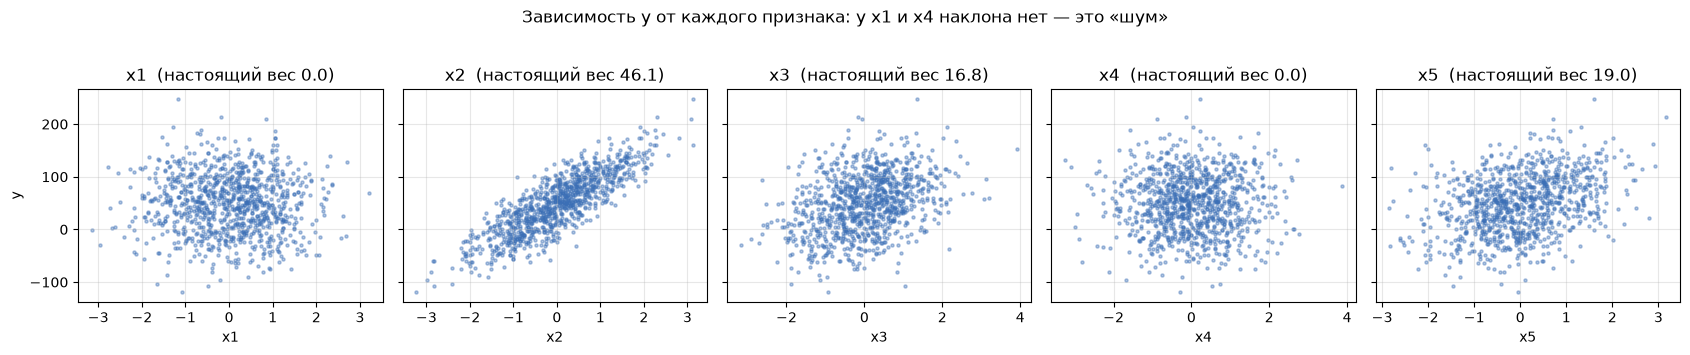

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for i, ax in enumerate(axes):
    ax.scatter(X_scaled[:, i], y, s=5, alpha=0.4, color="#3b6fb6")
    ax.set_title(f"{feature_names[i]}  (настоящий вес {true_coef[i]:.1f})")
    ax.set_xlabel(feature_names[i])
axes[0].set_ylabel("y")
plt.suptitle("Зависимость y от каждого признака: у x1 и x4 наклона нет — это «шум»", y=1.03)
plt.tight_layout(); plt.show()

**Эталон для сравнения.** Решение `LinearRegression` из sklearn — точное (аналитическое) решение задачи наименьших квадратов.
Наш градиентный спуск должен прийти к тем же весам.

In [6]:
ref = LinearRegression().fit(X_scaled, y)
w_ref = np.r_[ref.intercept_, ref.coef_]

def mse(X_b, y, w):
    # среднеквадратичная ошибка Q(w) = 1/n * ||Xw - y||^2
    return np.mean((X_b @ w - y) ** 2)

print("Веса LinearRegression:", w_ref.round(3))
print(f"MSE эталона: {mse(X_b, y, w_ref):.3f}   (≈ noise² = {15 ** 2})")

Веса LinearRegression: [48.893 -0.959 45.669 16.849 -0.287 19.751]
MSE эталона: 239.869   (≈ noise² = 225)


## 2. Функция градиентного спуска

Пишем строго по алгоритму из задания:
1. инициализируем веса нулями и задаём ε;
2. цикл по количеству итераций;
3. новые веса: $w^k = w^{k-1} - \eta \nabla Q$;
4. выходим, если $\|w^k - w^{k-1}\| < \varepsilon$.

Функция возвращает итоговые веса, **историю MSE** по итерациям (для графиков) и номер итерации, на которой остановились.

In [7]:
def gradient_descent(X_b, y, lr=0.1, eps=1e-6, max_iter=10_000):
    n, m = X_b.shape
    w = np.zeros(m)                          # 1) начальные веса
    history = [mse(X_b, y, w)]
    for k in range(1, max_iter + 1):         # 2) цикл по итерациям
        grad = 2 / n * X_b.T @ (X_b @ w - y) #    градиент MSE по ВСЕМ объектам
        w_new = w - lr * grad                # 3) новые веса
        history.append(mse(X_b, y, w_new))
        if not np.isfinite(history[-1]) or history[-1] > 1e12:  # спуск «улетел» (слишком большой шаг)
            return w_new, history, k
        if np.linalg.norm(w_new - w) < eps:  # 4) веса почти не меняются — стоп
            return w_new, history, k
        w = w_new
    return w, history, max_iter

In [8]:
w_gd, hist_gd, it_gd = gradient_descent(X_b, y, lr=0.1)

print(f"Остановились на итерации {it_gd}, MSE = {hist_gd[-1]:.3f}")
pd.DataFrame({"Градиентный спуск": w_gd, "LinearRegression": w_ref,
              "разница": w_gd - w_ref}, index=weight_names).round(4)

Остановились на итерации 76, MSE = 239.869


,Градиентный спуск,LinearRegression,разница
w0 (bias),48.8929,48.8929,-0.0
w1 (x1),-0.9593,-0.9593,-0.0
w2 (x2),45.6689,45.6689,-0.0
w3 (x3),16.8495,16.8495,0.0
w4 (x4),-0.2872,-0.2872,0.0
w5 (x5),19.7515,19.7515,-0.0


Веса совпали с точным решением `LinearRegression` до 4 знаков после запятой: функция работает правильно.
У признаков x1 и x4 веса близки к нулю — спуск сам «понял», что они не влияют на y (их настоящий вес 0).

## 3. Эксперимент со скоростью обучения

Скорость обучения $\eta$ (learning rate) — размер шага. Пробуем несколько значений и смотрим, как меняется ошибка.

In [9]:
learning_rates = [0.001, 0.01, 0.1, 0.5, 0.9, 1.05]
results = {}
rows = []
for lr in learning_rates:
    w, hist, it = gradient_descent(X_b, y, lr=lr, max_iter=5000)
    results[lr] = hist
    ok = np.isfinite(hist[-1]) and hist[-1] < 1e6   # огромная ошибка = спуск разошёлся
    rows.append({"скорость η": lr,
                 "итераций": it,
                 "итоговая MSE": round(hist[-1], 3) if ok else "∞ (расходится)",
                 "сошёлся": "да" if ok and it < 5000 else ("нет, не успел" if ok else "нет, разошёлся")})
pd.DataFrame(rows)

,скорость η,итераций,итоговая MSE,сошёлся
0,0.001,5000,239.869,"нет, не успел"
1,0.010,704,239.869,да
2,0.100,76,239.869,да
3,0.500,8,239.869,да
4,0.900,214,239.869,да
5,1.050,48,∞ (расходится),"нет, разошёлся"


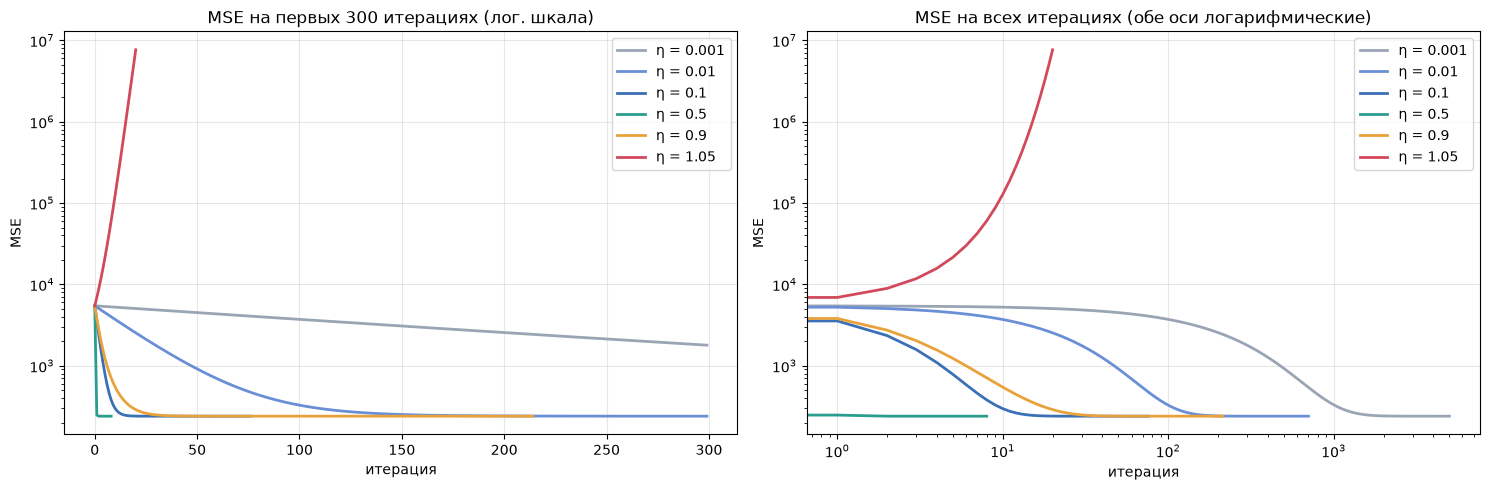

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = ["#9aa5b4", "#6b8fd6", "#3b6fb6", "#2a9d8f", "#e9a23b", "#d1495b"]
for (lr, hist), c in zip(results.items(), colors):
    h = np.array(hist, dtype=float)
    shown = h[: np.argmax(~np.isfinite(h) | (h > 1e7)) or len(h)]
    axes[0].plot(shown[:300], label=f"η = {lr}", color=c, lw=2)
    axes[1].plot(np.arange(len(shown)), shown, label=f"η = {lr}", color=c, lw=2)
axes[0].set_yscale("log"); axes[0].set_title("MSE на первых 300 итерациях (лог. шкала)")
axes[1].set_yscale("log"); axes[1].set_xscale("log"); axes[1].set_title("MSE на всех итерациях (обе оси логарифмические)")
for ax in axes:
    ax.set_xlabel("итерация"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.show()

**Выводы по скорости обучения:**
- **Слишком маленький шаг** (η = 0.001): спуск идёт верно, но очень медленно — за 5000 итераций условие остановки так и не выполнилось (ошибка почти у минимума, но веса всё ещё понемногу меняются); при η = 0.01 хватило 704 итераций.
- **Средний шаг** (η = 0.01 … 0.1): устойчивая сходимость; чем больше шаг, тем меньше итераций нужно.
- **Большой шаг** (η = 0.5): самая быстрая сходимость — за десяток итераций.
- **Слишком большой шаг** (η = 0.9 … 1.05): веса «перепрыгивают» минимум. При η = 0.9 ещё сходится, но с колебаниями
  и уже медленнее (200+ итераций вместо 8 при η = 0.5); при η > 1 каждый шаг уводит всё дальше от минимума,
  ошибка растёт до бесконечности — спуск **расходится**.
- Граница устойчивости зависит от данных: для стандартизированных признаков она около 1. Поэтому масштабирование
  так важно — без него «безопасный» шаг для одного признака оказывается гигантским для другого.

## 4. Стохастический градиентный спуск

Добавляем в функцию параметр `stochastic`. Если он включён, на каждой итерации градиент считается **по одному случайному объекту**:

$$\nabla Q_i(w) = 2\, x_i^T (x_i w - y_i).$$

Это в n раз дешевле, но градиент «шумный»: один объект плохо представляет всю выборку.
Поэтому:
- шаг постепенно уменьшаем: $\eta_k = \eta_0 / (1 + k \cdot decay)$ — в формуле из задания это и есть $\eta_k$, зависящий от итерации;
- правило остановки по $\|w^k - w^{k-1}\|$ для SGD ненадёжно (случайно маленький шаг ещё не значит, что дошли до минимума),
  поэтому SGD останавливается по числу итераций или когда шаг станет совсем маленьким.

In [11]:
def gradient_descent(X_b, y, lr=0.1, eps=1e-6, max_iter=10_000,
                     stochastic=False, decay=0.0, random_state=None):
    rng = np.random.default_rng(random_state)
    n, m = X_b.shape
    w = np.zeros(m)                                   # 1) начальные веса
    history = [mse(X_b, y, w)]
    for k in range(1, max_iter + 1):                  # 2) цикл по итерациям
        if stochastic:
            i = rng.integers(n)                       #    случайный объект
            xi, yi = X_b[i], y[i]
            grad = 2 * xi * (xi @ w - yi)             #    градиент по ОДНОМУ объекту
        else:
            grad = 2 / n * X_b.T @ (X_b @ w - y)      #    градиент по ВСЕМ объектам
        eta = lr / (1 + decay * k)                    #    шаг η_k (при decay=0 постоянный)
        w_new = w - eta * grad                        # 3) новые веса
        history.append(mse(X_b, y, w_new))
        if not np.isfinite(history[-1]) or history[-1] > 1e12:  # спуск «улетел»
            return w_new, history, k
        if np.linalg.norm(w_new - w) < eps:           # 4) условие остановки
            return w_new, history, k
        w = w_new
    return w, history, max_iter

## 5. Сравнение GD и SGD

Обучаем линейную модель обоими методами. Шаг для GD берём 0.1, для SGD — 0.01 с затуханием
(при одинаковом шаге SGD «прыгал» бы гораздо сильнее, потому что градиент по одному объекту большой и шумный).

In [12]:
w_gd, hist_gd, it_gd = gradient_descent(X_b, y, lr=0.1)
w_sgd, hist_sgd, it_sgd = gradient_descent(X_b, y, lr=0.01, stochastic=True, decay=0.002,
                                           eps=1e-8, max_iter=20_000, random_state=0)

n = len(y)
print(f"GD : итераций {it_gd:6d}, градиентов по объектам {it_gd * n:9d}, итоговая MSE {hist_gd[-1]:.3f}")
print(f"SGD: итераций {it_sgd:6d}, градиентов по объектам {it_sgd:9d}, итоговая MSE {hist_sgd[-1]:.3f}")
print(f"Эталон (LinearRegression) MSE {mse(X_b, y, w_ref):.3f}")

pd.DataFrame({"GD": w_gd, "SGD": w_sgd, "LinearRegression": w_ref}, index=weight_names).round(3)

GD : итераций     76, градиентов по объектам     76000, итоговая MSE 239.869
SGD: итераций  20000, градиентов по объектам     20000, итоговая MSE 240.357
Эталон (LinearRegression) MSE 239.869


,GD,SGD,LinearRegression
w0 (bias),48.893,48.847,48.893
w1 (x1),-0.959,-0.827,-0.959
w2 (x2),45.669,45.479,45.669
w3 (x3),16.849,17.296,16.849
w4 (x4),-0.287,-0.782,-0.287
w5 (x5),19.751,19.827,19.751


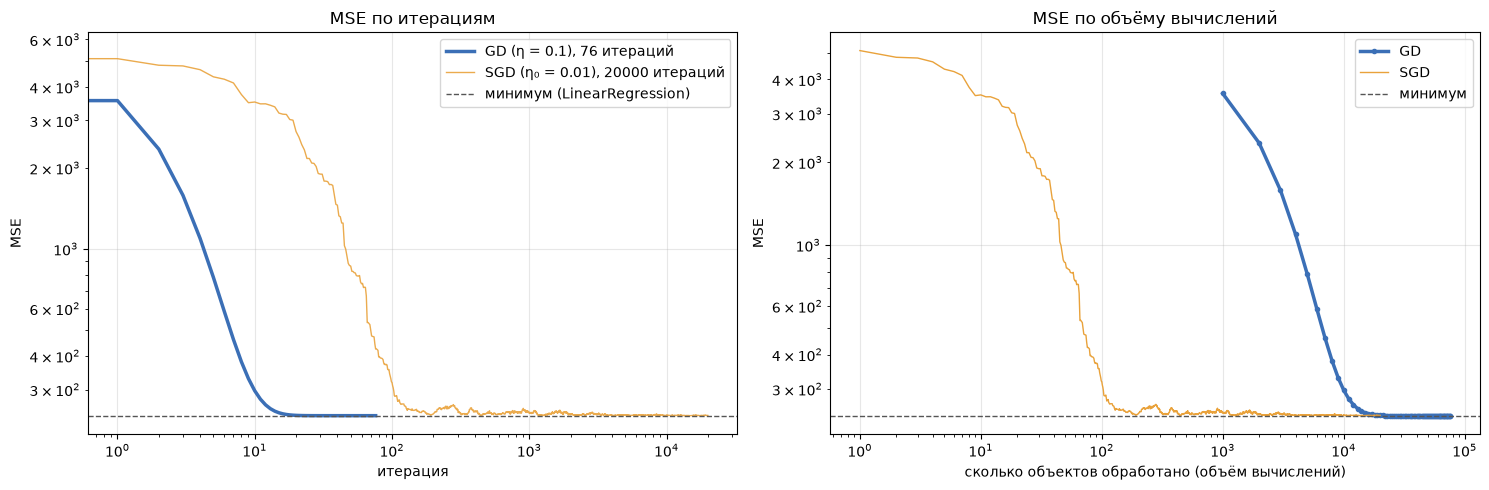

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(hist_gd, label=f"GD (η = 0.1), {it_gd} итераций", color="#3b6fb6", lw=2.5)
axes[0].plot(hist_sgd, label=f"SGD (η₀ = 0.01), {it_sgd} итераций", color="#e9a23b", lw=1, alpha=0.9)
axes[0].axhline(mse(X_b, y, w_ref), color="#555", ls="--", lw=1, label="минимум (LinearRegression)")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("итерация"); axes[0].set_ylabel("MSE")
axes[0].set_title("MSE по итерациям")
axes[0].legend()

# По горизонтали — сколько объектов обработано: одна итерация GD = n объектов, одна итерация SGD = 1 объект
axes[1].plot(np.arange(1, len(hist_gd)) * n, hist_gd[1:], label="GD", color="#3b6fb6", lw=2.5, marker="o", ms=3)
axes[1].plot(np.arange(1, len(hist_sgd)), hist_sgd[1:], label="SGD", color="#e9a23b", lw=1)
axes[1].axhline(mse(X_b, y, w_ref), color="#555", ls="--", lw=1, label="минимум")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("сколько объектов обработано (объём вычислений)"); axes[1].set_ylabel("MSE")
axes[1].set_title("MSE по объёму вычислений")
axes[1].legend()
plt.tight_layout(); plt.show()

**Выводы по сравнению GD и SGD:**
- **По числу итераций GD сходится намного быстрее**: ему хватает десятков итераций, SGD — тысяч.
  Каждый шаг GD точный (градиент по всей выборке), поэтому кривая гладкая.
- **Кривая SGD «шумная»**: градиент по одному объекту лишь приблизительно указывает направление, ошибка скачет вверх-вниз.
  Затухание шага успокаивает колебания к концу обучения.
- **По объёму вычислений картина обратная**: одна итерация GD обрабатывает все 1000 объектов, а SGD — один.
  Правый график показывает, что SGD снижает ошибку уже после первых сотен объектов, когда GD ещё не сделал и одного шага.
  На больших данных (миллионы объектов) поэтому используют SGD или мини-батчи.
- **Точность**: GD приходит ровно в минимум; SGD — в небольшую окрестность минимума (итоговая MSE чуть выше эталона),
  веса отличаются от точных в десятых долях.

## 6. L1-регуляризация (вариант 4 — чётный)

**Зачем.** Регуляризация штрафует модель за большие веса, чтобы она не переобучалась и не опиралась на бесполезные признаки.
L1-регуляризация (**Lasso**) добавляет к ошибке сумму модулей весов:

$$Q_{L1}(w) = \frac{1}{n}\|Xw - y\|^2 + \lambda \sum_{j=1}^{m} |w_j|.$$

- $\lambda$ — коэффициент регуляризации: чем он больше, тем сильнее веса прижимаются к нулю;
- свободный член $w_0$ **не штрафуем**: он отвечает за общий сдвиг, а не за влияние признаков.

**Главное свойство L1:** веса не просто уменьшаются, а становятся **ровно нулём**. Модель сама отбирает признаки:
сначала обнуляются бесполезные (у нас x4, x5), при большом $\lambda$ — все.
(L2-регуляризация, для нечётных вариантов, штрафует $\lambda\sum w_j^2$ и только уменьшает веса, не обнуляя.)

**Как это реализовать в градиентном спуске.** Производная $|w|$ — это $\text{sign}(w)$, но в нуле она не определена,
и при простом шаге $w - \eta\lambda\,\text{sign}(w)$ вес «прыгает» вокруг нуля, никогда не становясь нулём.
Поэтому шаг делаем в два этапа (метод **ISTA**, проксимальный градиентный спуск):
1. обычный шаг по градиенту MSE: $z = w - \eta \nabla \text{MSE}$;
2. «мягкий порог» (soft thresholding): каждый вес приближаем к нулю на $\eta\lambda$, а если он был меньше этой величины — ставим ровно 0:

$$w_j = \text{sign}(z_j)\cdot\max(|z_j| - \eta\lambda,\ 0).$$

In [14]:
def soft_threshold(z, t):
    # приблизить каждое значение к нулю на t; то, что ближе к нулю, чем t, — обнулить
    return np.sign(z) * np.maximum(np.abs(z) - t, 0.0)


def gradient_descent_l1(X_b, y, lam, lr=0.1, eps=1e-8, max_iter=20_000):
    n, m = X_b.shape
    w = np.zeros(m)                                        # 1) начальные веса
    for k in range(1, max_iter + 1):                       # 2) цикл
        grad = 2 / n * X_b.T @ (X_b @ w - y)               #    градиент MSE
        z = w - lr * grad                                  # 3a) обычный шаг
        w_new = z.copy()
        w_new[1:] = soft_threshold(z[1:], lr * lam)        # 3b) L1: мягкий порог (кроме bias)
        if np.linalg.norm(w_new - w) < eps:                # 4) стоп
            return w_new, k
        w = w_new
    return w, max_iter

Проверим на одном значении $\lambda$, что реализация верная: сравним со `sklearn.linear_model.Lasso`.
У sklearn функция потерь записана как $\frac{1}{2n}\|Xw-y\|^2 + \alpha\|w\|_1$ — это наша формула, делённая на 2,
поэтому нашему $\lambda$ соответствует $\alpha = \lambda / 2$.

In [15]:
lam = 10
w_l1, it = gradient_descent_l1(X_b, y, lam=lam)
sk = Lasso(alpha=lam / 2).fit(X_scaled, y)
pd.DataFrame({"наш GD + L1": w_l1, "sklearn Lasso": np.r_[sk.intercept_, sk.coef_], "без регуляризации": w_ref},
             index=weight_names).round(3)

,наш GD + L1,sklearn Lasso,без регуляризации
w0 (bias),48.893,48.893,48.893
w1 (x1),-0.000,-0.000,-0.959
w2 (x2),40.912,40.912,45.669
w3 (x3),12.035,12.035,16.849
w4 (x4),-0.000,-0.000,-0.287
w5 (x5),14.639,14.639,19.751


Совпадает со sklearn. При $\lambda = 10$ веса бесполезных признаков x1 и x4 стали **ровно 0**, а полезные лишь немного уменьшились.

### 20 коэффициентов регуляризации от 0.001 до 1000

`np.logspace(-3, 3, 20)` даёт 20 чисел, равномерно расположенных по **логарифмической** шкале: 0.001, 0.002, … , 1000.
Так в диапазон попадают и очень слабая, и очень сильная регуляризация.

In [16]:
lambdas = np.logspace(-3, 3, 20)
path = []
for lam in lambdas:
    w, _ = gradient_descent_l1(X_b, y, lam=lam)
    path.append(w)
path = np.array(path)

table = pd.DataFrame(path, columns=weight_names)
table.insert(0, "λ", lambdas)
table["нулевых весов"] = (np.abs(path[:, 1:]) < 1e-10).sum(axis=1)
table["MSE"] = [mse(X_b, y, w) for w in path]
table.round(3)

,λ,w0 (bias),w1 (x1),w2 (x2),w3 (x3),w4 (x4),w5 (x5),нулевых весов,MSE
0,0.001,48.893,-0.959,45.668,16.849,-0.287,19.751,0,239.869
1,0.002,48.893,-0.958,45.668,16.848,-0.286,19.750,0,239.869
2,0.004,48.893,-0.957,45.667,16.847,-0.285,19.749,0,239.869
3,0.009,48.893,-0.955,45.665,16.845,-0.283,19.747,0,239.869
4,0.018,48.893,-0.950,45.660,16.841,-0.278,19.742,0,239.869
5,0.038,48.893,-0.941,45.651,16.831,-0.268,19.732,0,239.870
6,0.078,48.893,-0.921,45.632,16.811,-0.246,19.712,0,239.876
7,0.162,48.893,-0.880,45.592,16.771,-0.203,19.669,0,239.901
8,0.336,48.893,-0.795,45.509,16.687,-0.113,19.581,0,240.008
9,0.695,48.893,-0.620,45.339,16.514,-0.000,19.400,1,240.419


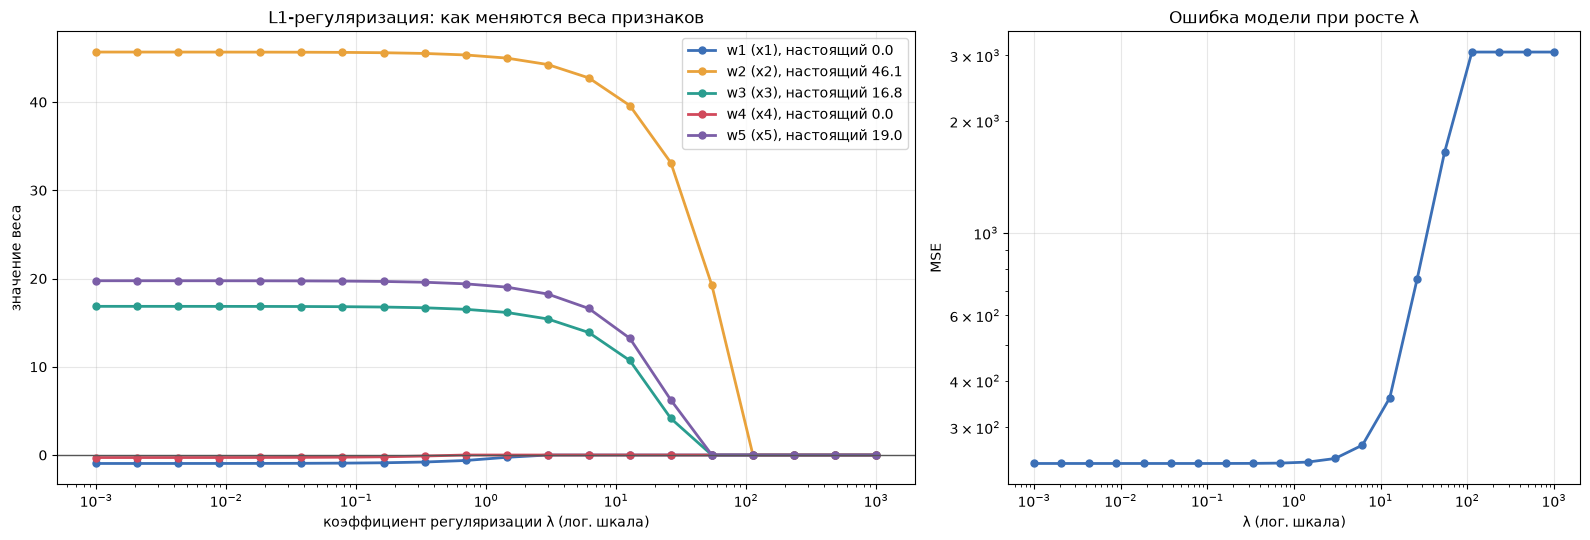

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [3, 2]})
palette = ["#3b6fb6", "#e9a23b", "#2a9d8f", "#d1495b", "#7b5ea7"]
for j in range(1, path.shape[1]):
    axes[0].plot(lambdas, path[:, j], marker="o", ms=5, lw=2, color=palette[j - 1],
                 label=f"{weight_names[j]}, настоящий {true_coef[j - 1]:.1f}")
axes[0].axhline(0, color="#555", lw=1)
axes[0].set_xscale("log")
axes[0].set_xlabel("коэффициент регуляризации λ (лог. шкала)")
axes[0].set_ylabel("значение веса")
axes[0].set_title("L1-регуляризация: как меняются веса признаков")
axes[0].legend()

axes[1].plot(lambdas, table["MSE"], marker="o", ms=5, lw=2, color="#3b6fb6")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("λ (лог. шкала)"); axes[1].set_ylabel("MSE")
axes[1].set_title("Ошибка модели при росте λ")
plt.tight_layout(); plt.show()

**Выводы по L1-регуляризации:**
- **Маленькие λ (0.001 … 0.3)**: штраф почти не действует, веса совпадают с обычной линейной регрессией, MSE не меняется.
- **λ ≈ 0.7 … 3**: первыми становятся **ровно нулевыми** веса бесполезных признаков x4, затем x1 — L1 сама отбирает признаки.
  Ошибка при этом почти не растёт: эти признаки и так ничего не давали.
- **λ ≈ 6 … 55**: уменьшаются полезные признаки, сначала обнуляются самые слабые (x3, x5), дольше всех держится самый сильный x2.
  Ошибка заметно растёт — модель становится слишком простой (недообучение).
- **λ ≥ ≈ 110**: все веса признаков равны нулю, модель предсказывает просто среднее значение y (остался только $w_0$), MSE максимальна.
- Отличие от L2: L2 уменьшала бы веса плавно, но **не обнуляла** их. Поэтому L1 используют, когда нужно ещё и отобрать признаки.
- λ — гиперпараметр: на практике его подбирают на валидационной выборке (кросс-валидацией), выбирая баланс между точностью и простотой модели.

## Общие выводы

1. Сгенерирован датасет из 1000 объектов и 5 признаков (6 весов вместе со свободным членом), признаки стандартизированы.
2. Реализован градиентный спуск по алгоритму из задания: начальные веса и ε, цикл, шаг $w^k = w^{k-1} - \eta\nabla Q$,
   остановка по $\|w^k - w^{k-1}\| < \varepsilon$. Полученные веса совпали с точным решением `LinearRegression`.
3. Скорость обучения определяет поведение спуска: маленькая — медленная сходимость, средняя — быстрая и устойчивая,
   слишком большая (η > 1 для наших данных) — расхождение.
4. Добавлен режим стохастического спуска (случайный объект на каждой итерации, затухающий шаг).
5. GD сходится за меньшее число итераций и гладко, SGD — за большее число итераций и с колебаниями,
   но каждая его итерация в n раз дешевле, поэтому по объёму вычислений SGD снижает ошибку быстрее.
6. Реализована L1-регуляризация (проксимальный шаг с мягким порогом), проверена по `sklearn.Lasso`.
   С ростом λ веса уменьшаются и обнуляются: сначала у бесполезных признаков, затем у всех.